# Лабораторная работа 3. Доверительные интервалы и проверка гипотез

**Перерва П. Д., группа 421702**

## 1. Первичная обработка данных

Используем данные **National Health and Nutrition Examination Survey (NHANES), 2013–2014**. Цель работы — оценить среднее и медиану первого измерения систолического артериального давления (САД) у взрослых и выяснить, меняется ли САД при повторном измерении во время того же обследования. Уникальность выбора набора внутри группы не проверена.

Загружаем исходные таблицы CDC: возраст участника (`DEMO_H.xpt`), измерения давления (`BPX_H.xpt`) и ответы анкеты (`BPQ_H.xpt`). Файлы находятся в папке `data` рядом с ноутбуком. При запуске без этой папки таблицы загружаются из открытого каталога CDC.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

%matplotlib inline

# 1. Загрузка и объединение исходных таблиц
data_dir = Path("data")
cdc_url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/"


def read_nhanes(filename, columns):
    local_file = data_dir / filename
    source = local_file if local_file.is_file() else cdc_url + filename
    return pd.read_sas(source, format="xport")[columns]


demographics = read_nhanes("DEMO_H.xpt", ["SEQN", "RIDAGEYR"])
pressure = read_nhanes("BPX_H.xpt", ["SEQN", "BPXSY1", "BPXSY2"])
questionnaire = read_nhanes("BPQ_H.xpt", ["SEQN", "BPQ020"])

raw = (
    demographics
    .merge(pressure, on="SEQN", how="left", validate="one_to_one")
    .merge(questionnaire, on="SEQN", how="left", validate="one_to_one")
)

# При чтении XPT нулевой возраст иногда представлен числом порядка 10⁻⁷⁹.
age_years = raw["RIDAGEYR"].round()
np.testing.assert_allclose(raw["RIDAGEYR"], age_years, rtol=0, atol=1e-12)
raw["RIDAGEYR"] = age_years
raw = raw.astype("Int64")

# 2. Первые строки, типы и пропуски
print(f"После объединения: {raw.shape[0]} строк × {raw.shape[1]} столбцов.")
display(raw.head())
display(pd.DataFrame({"Тип": raw.dtypes.astype(str), "Пропуски": raw.isna().sum()}))

После объединения: 10175 строк × 5 столбцов.


,SEQN,RIDAGEYR,BPXSY1,BPXSY2,BPQ020
0,73557,69,122,114,1
1,73558,54,156,160,1
2,73559,72,140,140,1
3,73560,9,108,102,<NA>
4,73561,73,136,134,1


,Тип,Пропуски
SEQN,Int64,0
RIDAGEYR,Int64,0
BPXSY1,Int64,3003
BPXSY2,Int64,2766
BPQ020,Int64,3711


После объединения одна строка соответствует одному участнику с идентификатором `SEQN`. `RIDAGEYR` — возраст в полных годах, где 80 означает «80 лет и старше». `BPXSY1` и `BPXSY2` — два последовательных измерения САД в мм рт. ст. `BPQ020` — ответ на вопрос, сообщал ли участнику медработник о гипертонии. Коды 1 и 2 означают «да» и «нет», 7 и 9 — «отказ» и «не знаю».

Оставляем участников от 18 лет. Для основной выборки требуется первое измерение, для парного теста — оба измерения в строке с одним `SEQN`. В тест Уэлча входят участники с первым измерением и ответом «да» или «нет». Для χ² достаточно возраста и определённого ответа. Используем доступные наблюдения по каждой задаче. Заполнение пропусков могло бы изменить вариацию давления и создать искусственные пары.

In [2]:
# 3. Проверка допустимых значений и подготовка выборок
assert raw[["SEQN", "RIDAGEYR"]].notna().all().all()
assert raw["RIDAGEYR"].between(0, 80).all()
assert raw["BPQ020"].dropna().isin([1, 2, 7, 9]).all()
for column in ["BPXSY1", "BPXSY2"]:
    readings = raw[column].dropna()
    assert readings.between(1, 300).all() and readings.mod(2).eq(0).all()

adults = raw.loc[raw["RIDAGEYR"].ge(18)].copy()
adults["Ответ"] = adults["BPQ020"].map({1: "Да", 2: "Нет"})
first = adults.dropna(subset=["BPXSY1"])
welch_data = first.dropna(subset=["Ответ"])
paired = adults.set_index("SEQN").dropna(subset=["BPXSY1", "BPXSY2"])
chi_data = adults.dropna(subset=["Ответ"]).copy()

volume = pd.DataFrame([
    ("Возраст ≥ 18 лет", len(raw), len(adults)),
    ("Основная выборка, первое САД", len(adults), len(first)),
    ("Уэлч, первое САД и ответ", len(first), len(welch_data)),
    ("Парный тест, оба САД", len(adults), len(paired)),
    ("χ², возраст и определённый ответ", len(adults), len(chi_data)),
], columns=["Выборка", "До отбора", "После отбора"]).set_index("Выборка")
volume["Исключено"] = volume["До отбора"] - volume["После отбора"]
display(volume)
print(f"У взрослых пустых BPQ020: {adults['BPQ020'].isna().sum()}. "
      f"Кодов отказа / «не знаю»: {adults['BPQ020'].isin([7, 9]).sum()}.")

,До отбора,После отбора,Исключено
Выборка,,,
Возраст ≥ 18 лет,10175,6113,4062
"Основная выборка, первое САД",6113,5426,687
"Уэлч, первое САД и ответ",5426,5421,5
"Парный тест, оба САД",6113,5351,762
"χ², возраст и определённый ответ",6113,6108,5


У взрослых пустых BPQ020: 0. Кодов отказа / «не знаю»: 5.


**Вывод по первичной обработке данных.** Из 10 175 участников 6 113 достигли 18 лет. Первое САД доступно у 5 426 взрослых, оба измерения — у 5 351. Для теста Уэлча подходят 5 421 наблюдение с известным ответом на вопрос о гипертонии. В таблицу для χ² вошли 6 108 взрослых.

## 2. Разведочный анализ данных (EDA)

САД — количественная величина на непрерывной шкале. В NHANES показания округляли до чётного числа мм рт. ст. Рассчитаем описательные статистики для первого измерения и оценим распределение по гистограмме, ящику с усами и нормальному Q–Q графику.

In [3]:
# Описательные статистики первого измерения
unit = "мм рт. ст."
x = first["BPXSY1"].to_numpy(dtype=float)
n = x.size
x_mean = x.mean()
x_median = np.median(x)
s = x.std(ddof=1)


def describe(values):
    q1, q2, q3 = np.quantile(values, [0.25, 0.50, 0.75])
    iqr = q3 - q1
    return {
        "n": len(values),
        "Среднее": values.mean(),
        "Медиана": q2,
        "s (ddof=1)": values.std(ddof=1),
        "Q1": q1,
        "Q2": q2,
        "Q3": q3,
        "Минимум": values.min(),
        "Максимум": values.max(),
        "Асимметрия": stats.skew(values, bias=False),
        "Ниже нижнего уса": np.count_nonzero(values < q1 - 1.5 * iqr),
        "Выше верхнего уса": np.count_nonzero(values > q3 + 1.5 * iqr),
    }


display(pd.DataFrame.from_dict(
    {"Первое САД": describe(x)}, orient="index"
).T.rename_axis(f"Показатели САД ({unit} для размерных статистик)").round(3))

,Первое САД
Показатели САД (мм рт. ст. для размерных статистик),
n,5426.000
Среднее,122.452
Медиана,120.000
s (ddof=1),17.967
Q1,110.000
Q2,120.000
Q3,132.000
Минимум,66.000
Максимум,228.000


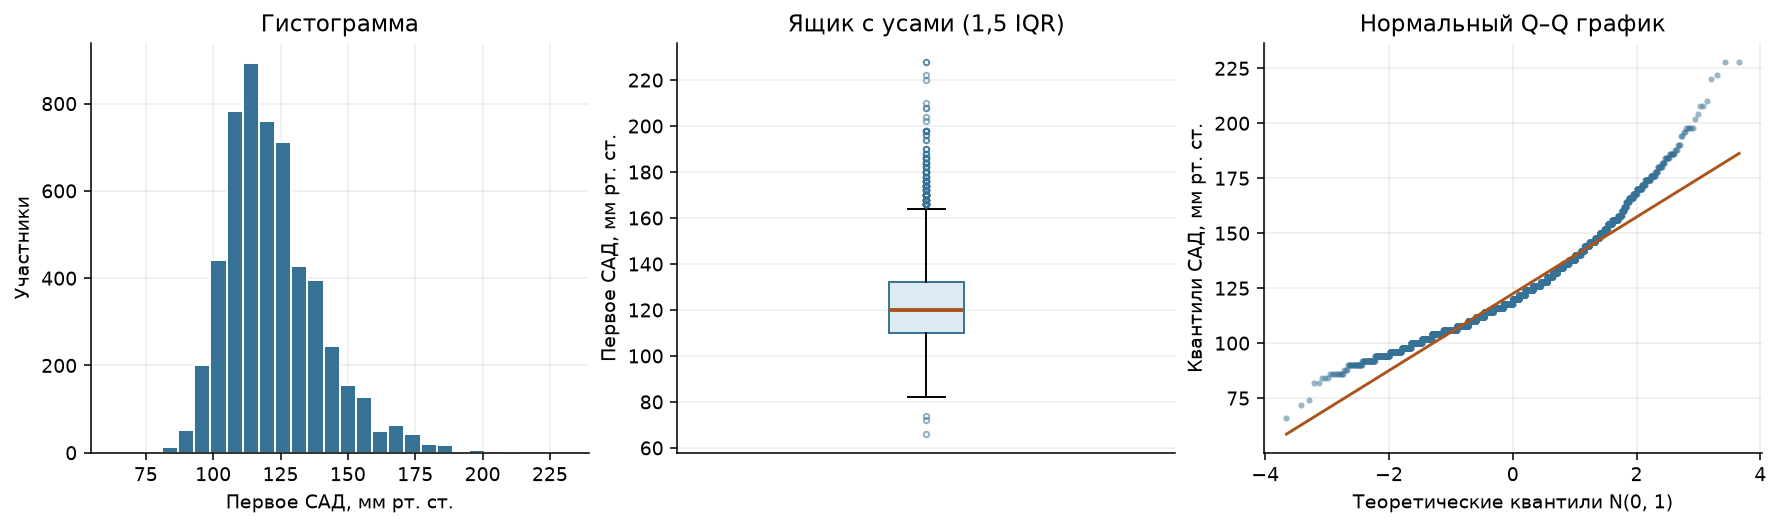

In [4]:
# Гистограмма, ящик с усами и Q–Q график

plt.rcParams.update({
    "figure.dpi": 140,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "legend.frameon": False,
})

blue, teal, orange, purple = "#367196", "#174F49", "#AB551D", "#72477F"


def qq_plot(ax, values, title, ylabel):
    (theoretical, sample), (slope, intercept, _) = stats.probplot(values, dist="norm")
    ax.scatter(theoretical, sample, s=10, alpha=0.50, color=blue, linewidths=0)
    ax.plot(theoretical, intercept + slope * theoretical, color=orange, lw=1.5)
    ax.set(title=title, xlabel="Теоретические квантили N(0, 1)", ylabel=ylabel)


fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.65), layout="constrained")
axes[0].hist(x, bins=np.arange(63, 236, 6), color=blue, edgecolor="white")
axes[0].set(title="Гистограмма", xlabel=f"Первое САД, {unit}", ylabel="Участники")
axes[1].boxplot(
    x, whis=1.5, patch_artist=True,
    boxprops={"facecolor": "#DCEBF2", "color": blue},
    medianprops={"color": orange, "linewidth": 2},
    flierprops={"markersize": 2.8, "markeredgecolor": blue, "alpha": 0.55},
)
axes[1].set(title="Ящик с усами (1,5 IQR)", ylabel=f"Первое САД, {unit}", xticks=[])
qq_plot(axes[2], x, "Нормальный Q–Q график", f"Квантили САД, {unit}")
plt.show()

**Выводы по разведочному анализу.** Первое САД имеет один основной максимум, длинный правый хвост и положительную асимметрию (1,079). Среднее 122,45 мм рт. ст. выше медианы 120. За верхним усом находятся 164 наблюдения, за нижним — 3. На Q–Q графике наиболее заметно отклонение верхних квантилей. При $n=5426$ и конечном разбросе центральная предельная теорема обосновывает приближённый t-вывод о среднем в модели независимых наблюдений. Для ДИ дисперсии по χ² нужна более строгая предпосылка нормальности, поэтому этот опциональный интервал опущен.

## 3. Параметрические доверительные интервалы

Для неизвестной дисперсии считаем $SE=s/\sqrt n$ и интервал
$$
\bar{x}\ \pm\ t_{1-\alpha/2,\,n-1}\,\frac{s}{\sqrt{n}}.
$$
Для каждого уровня берём соответствующий квантиль с $n-1$ степенью свободы.

In [5]:
def t_interval(center, se, df, confidence=0.95):
    critical = stats.t.ppf((1 + confidence) / 2, df)
    margin = critical * se
    return center - margin, center + margin


se = s / np.sqrt(n)
t95 = t_interval(x_mean, se, n - 1)
t99 = t_interval(x_mean, se, n - 1, confidence=0.99)

parametric = pd.DataFrame([
    (f"{level:.0%}", n, x_mean, se, *ci, ci[1] - ci[0])
    for level, ci in [(0.95, t95), (0.99, t99)]
], columns=["Уровень", "n", "Среднее", "SE", "Нижняя", "Верхняя", "Ширина"])
display(parametric.set_index("Уровень").round(4))

,n,Среднее,SE,Нижняя,Верхняя,Ширина
Уровень,,,,,,
95%,5426,122.4515,0.2439,121.9734,122.9297,0.9563
99%,5426,122.4515,0.2439,121.8230,123.0800,1.2570


## 4. Бутстреп и сравнение интервалов

Бутстреп выбирает участников из основной выборки с возвращением. Каждая из $B=10\,000$ псевдовыборок имеет размер $n$. По одним и тем же псевдовыборкам считаем средние и медианы. Стандартная ошибка каждой статистики равна стандартному отклонению соответствующих репликаций с делителем $B-1$. Генератор инициализируем фиксированным seed, а вычисления делим на блоки по 256 псевдовыборок.

Нормальный 95% бутстреп-интервал для среднего равен $\bar{x}\pm z_{0{,}975} SE_{\mathrm{boot}}$ и центрирован в исходном среднем. Процентильные интервалы для среднего и медианы используют квантили 0,025 и 0,975 соответствующих репликаций.

In [6]:
seed, B, batch_size = 20261126, 10_000, 256


def bootstrap(values, repetitions, random_seed, batch):
    rng = np.random.default_rng(random_seed)
    means = np.empty(repetitions)
    medians = np.empty(repetitions)
    for start in range(0, repetitions, batch):
        stop = min(start + batch, repetitions)
        draws = rng.choice(values, size=(stop - start, values.size), replace=True)
        means[start:stop] = draws.mean(axis=1)
        medians[start:stop] = np.median(draws, axis=1)
    return means, medians


boot_means, boot_medians = bootstrap(x, B, seed, batch_size)
se_boot_mean = boot_means.std(ddof=1)
se_boot_median = boot_medians.std(ddof=1)
halfwidth_boot = stats.norm.ppf(0.975) * se_boot_mean
boot_normal = (x_mean - halfwidth_boot, x_mean + halfwidth_boot)
boot_mean_pct = np.quantile(boot_means, [0.025, 0.975])
boot_median_pct = np.quantile(boot_medians, [0.025, 0.975])

display(pd.DataFrame({
    "Исходная оценка": [x_mean, x_median],
    "Бутстреп-SE": [se_boot_mean, se_boot_median],
    "Асимметрия репликаций": [
        stats.skew(boot_means, bias=False), stats.skew(boot_medians, bias=False)
    ],
}, index=["Среднее", "Медиана"]).round(4))

,Исходная оценка,Бутстреп-SE,Асимметрия репликаций
Среднее,122.4515,0.2439,0.0188
Медиана,120.0000,0.9816,-0.3236


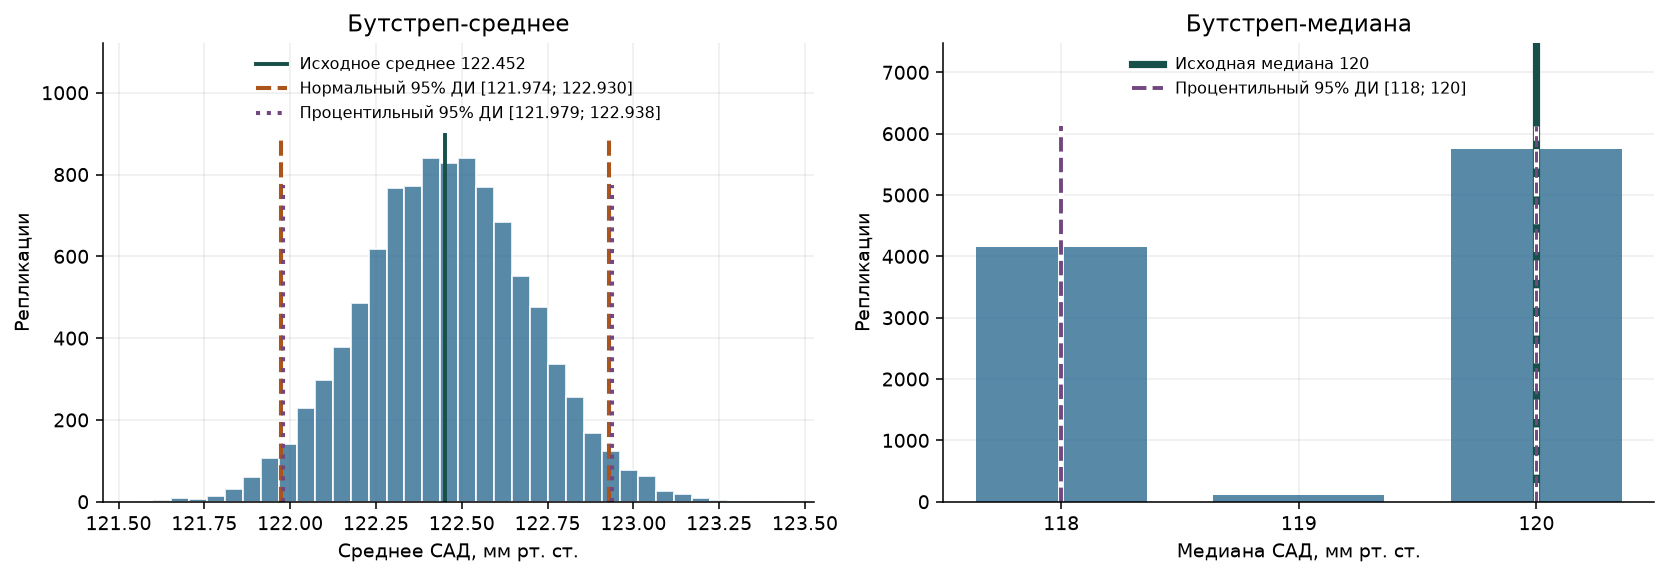

In [7]:
fig, (ax_mean, ax_median) = plt.subplots(1, 2, figsize=(11.8, 4.0), layout="constrained")
ax_mean.hist(boot_means, bins=36, color=blue, alpha=0.83, edgecolor="white")
ax_mean.axvline(x_mean, ymax=0.80, color=teal, lw=2,
                label=f"Исходное среднее {x_mean:.3f}")
for interval, height, color, style, label in [
    (boot_normal, 0.80, orange, "--", "Нормальный 95% ДИ"),
    (boot_mean_pct, 0.69, purple, ":", "Процентильный 95% ДИ"),
]:
    lo, hi = interval
    ax_mean.axvline(lo, ymax=height, color=color, linestyle=style, lw=2.1,
                    label=f"{label} [{lo:.3f}; {hi:.3f}]")
    ax_mean.axvline(hi, ymax=height, color=color, linestyle=style, lw=2.1)
ax_mean.set(title="Бутстреп-среднее", xlabel=f"Среднее САД, {unit}", ylabel="Репликации")
ax_mean.legend(loc="upper center", fontsize=8)
ax_mean.set_ylim(top=ax_mean.get_ylim()[1] * 1.27)

median_bins = np.arange(boot_medians.min() - 0.5, boot_medians.max() + 1.0, 1)
ax_median.hist(boot_medians, bins=median_bins, rwidth=0.72, color=blue, alpha=0.83)
median_lo, median_hi = boot_median_pct
ax_median.axvline(x_median, color=teal, lw=3.7,
                  label=f"Исходная медиана {x_median:g}")
ax_median.axvline(median_lo, ymax=0.82, color="white", lw=3)
ax_median.axvline(median_lo, ymax=0.82, color=purple, lw=2, linestyle="--",
                  label=f"Процентильный 95% ДИ [{median_lo:g}; {median_hi:g}]")
ax_median.axvline(median_hi, ymax=0.82, color="white", lw=2.7, linestyle="--")
ax_median.axvline(median_hi, ymax=0.82, color=purple, lw=1.5, linestyle="--")
ax_median.set(
    title="Бутстреп-медиана", xlabel=f"Медиана САД, {unit}", ylabel="Репликации",
    xticks=np.unique(boot_medians),
)
ax_median.legend(loc="upper center", fontsize=8)
ax_median.set_ylim(top=ax_median.get_ylim()[1] * 1.24)
plt.show()

In [8]:
interval_rows = [
    ("Стьюдент", "Среднее", x_mean, 0.95, t95),
    ("Стьюдент", "Среднее", x_mean, 0.99, t99),
    ("Бутстреп, нормальный", "Среднее", x_mean, 0.95, boot_normal),
    ("Бутстреп, процентильный", "Среднее", x_mean, 0.95, boot_mean_pct),
    ("Бутстреп, процентильный", "Медиана", x_median, 0.95, boot_median_pct),
]
intervals = pd.DataFrame([
    (method, estimand, f"{level:.0%}", lo, hi, hi - lo, center - lo, hi - center)
    for method, estimand, center, level, (lo, hi) in interval_rows
], columns=[
    "Метод", "Параметр", "Уровень", "Нижняя", "Верхняя", "Ширина",
    "От оценки до нижней", "От оценки до верхней",
])
display(intervals.round(4).set_index(["Метод", "Параметр", "Уровень"]))

Нижняя   Верхняя  Ширина  \
Метод                   Параметр Уровень                               
Стьюдент                Среднее  95%      121.9734  122.9297  0.9563   
                                 99%      121.8230  123.0800  1.2570   
Бутстреп, нормальный    Среднее  95%      121.9735  122.9295  0.9560   
Бутстреп, процентильный Среднее  95%      121.9790  122.9377  0.9588   
                        Медиана  95%      118.0000  120.0000  2.0000   

                                          От оценки до нижней  \
Метод                   Параметр Уровень                        
Стьюдент                Среднее  95%                   0.4782   
                                 99%                   0.6285   
Бутстреп, нормальный    Среднее  95%                   0.4780   
Бутстреп, процентильный Среднее  95%                   0.4726   
                        Медиана  95%                   2.0000   

                                          От оценки до верхней  
Метод                   Параметр Уровень                        
Стьюдент                Среднее  95%                    0.4782  
                                 99%                    0.6285  
Бутстреп, нормальный    Среднее  95%                    0.4780  
Бутстреп, процентильный Среднее  95%                    0.4862  
                        Медиана  95%                    0.0000

**Выводы по сравнению интервалов.** 95% t-интервал для среднего равен [121,9734; 122,9297] мм рт. ст., нормальный бутстреп-интервал — [121,9735; 122,9295], процентильный — [121,9790; 122,9377]. Ширины составляют 0,9563, 0,9560 и 0,9588 мм рт. ст. соответственно. Первые два симметричны относительно 122,4515. В процентильном интервале расстояние вправо составляет 0,4862, влево — 0,4726 мм рт. ст. Сильная правая асимметрия отдельных показаний слабо проявляется у бутстреп-средних (асимметрия 0,019). При большом $n$ это согласуется с почти одинаковыми стандартными ошибками. Разница между вычисленными границами также чувствительна к конечному числу репликаций.

99% t-интервал [121,8230; 123,0800] шире 95% примерно на 0,301 мм рт. ст., поскольку при том же SE более высокий уровень покрытия требует большего критического квантиля. Все три 95% интервала для среднего лежат выше ориентира 120 мм рт. ст. Предметный вывод о сравнении среднего с ориентиром устойчив к выбору метода.

Процентильный ДИ [118; 120] мм рт. ст. относится к медиане распределения первых показаний, то есть к уровню, делящему распределение пополам. Шаг записи и большое число совпадающих значений делают распределение бутстреп-медианы ступенчатым. Исходная медиана и верхняя граница совпали в точке 120.

## 5. Проверка гипотез

Проводим четыре проверки при уровне значимости $\alpha=0{,}05$. Разные значения `SEQN` обозначают разных участников. В учебной модели считаем их наблюдения независимыми и используем невзвешенные оценки. Для обобщения результатов на население США нужно учитывать веса, стратификацию и кластеры NHANES.

### 5.1. Одновыборочный t-тест

Пусть $\mu$ — среднее первого САД в рассматриваемой модели взрослых участников. Проверяем $H_0:\mu=120$ против $H_1:\mu\ne120$. Словами, нулевая гипотеза задаёт равенство среднего ориентиру 120 мм рт. ст., альтернативная допускает отклонение в любую сторону. Каждому участнику соответствует одно первое показание. Для среднего используем t-приближение при большом $n$ с оговоркой о плане NHANES из начала раздела 5. Стандартизированный эффект $d=(\bar{x}-\mu_0)/s$ выражает отклонение от ориентира в единицах выборочного стандартного отклонения.

Ориентир 120 мм рт. ст. соответствует одной из границ категорий САД в таблицах NCHS за 2014 год.

In [9]:
alpha = 0.05
mu0 = 120


def decision(pvalue):
    if pvalue < alpha:
        return "Отвергаем H₀"
    return "Недостаточно оснований отвергнуть H₀"


def format_ci(interval):
    return f"[{interval[0]:.3f}; {interval[1]:.3f}]"


def report_t(result, volume_text, estimate, interval, effect, effect_name):
    print(volume_text)
    print(f"t = {result.statistic:.4f}, df = {result.df:.3f}, p = {result.pvalue:.3e}.")
    print(f"Эффект = {estimate:+.3f} {unit}, 95% ДИ {format_ci(interval)} {unit}")
    print(f"{effect_name} = {effect:+.3f}. {decision(result.pvalue)}.")


one_test = stats.ttest_1samp(x, popmean=mu0, alternative="two-sided")
one_effect = x_mean - mu0
one_ci = tuple(bound - mu0 for bound in t95)
one_d = one_effect / s
report_t(one_test, f"n = {n}, ориентир = {mu0} {unit}", one_effect, one_ci, one_d, "d")
print(f"95% ДИ для самого среднего {format_ci(t95)} {unit} "
      f"Входит ли {mu0}: {'да' if t95[0] <= mu0 <= t95[1] else 'нет'}.")

n = 5426, ориентир = 120 мм рт. ст.
t = 10.0507, df = 5425.000, p = 1.465e-23.
Эффект = +2.452 мм рт. ст., 95% ДИ [1.973; 2.930] мм рт. ст.
d = +0.136. Отвергаем H₀.
95% ДИ для самого среднего [121.973; 122.930] мм рт. ст. Входит ли 120: нет.


**Вывод по одновыборочному t-тесту.** Среднее первого САД превышает ориентир на 2,452 мм рт. ст. при $s=17{,}967$ мм рт. ст. и $d=0{,}136$. Это небольшое отклонение на фоне межиндивидуального разброса. 120 находится ниже нижней границы 95% t-интервала для среднего, что согласуется с исходным двусторонним p-значением.

### 5.2. Тест Уэлча для независимых групп

Пусть $\mu_{\text{да}}$ и $\mu_{\text{нет}}$ — средние первых показаний у участников с ответами «да» и «нет» на вопрос BPQ020. Проверяем $H_0:\mu_{\text{да}}-\mu_{\text{нет}}=0$ против $H_1:\mu_{\text{да}}-\mu_{\text{нет}}\ne0$. Нулевая гипотеза утверждает равенство, альтернативная — различие средних. Порядок вычитания — «да» минус «нет».

Каждый участник входит только в одну группу и даёт одно измерение. Допускаем разные дисперсии. Сопоставление наблюдательное, поэтому нескорректированная разность средних может отражать возраст, лечение и другие различия состава групп. Для интервала берём $SE=\sqrt{v_1+v_2}$, где $v_g=s_g^2/n_g$, и степени свободы Уэлча — Саттертуэйта
$$
\nu=\frac{(v_1+v_2)^2}{v_1^2/(n_1-1)+v_2^2/(n_2-1)}.
$$
Для стандартизации делим оценку разности на $\sqrt{(s_1^2+s_2^2)/2}$.

,Сообщали,Не сообщали
n,1867.000,3554.000
Среднее,131.875,117.494
Медиана,130.000,116.000
s (ddof=1),19.823,14.649
Q1,118.000,108.000
Q2,130.000,116.000
Q3,144.000,126.000
Минимум,66.000,74.000
Максимум,228.000,210.000
Асимметрия,0.746,1.118


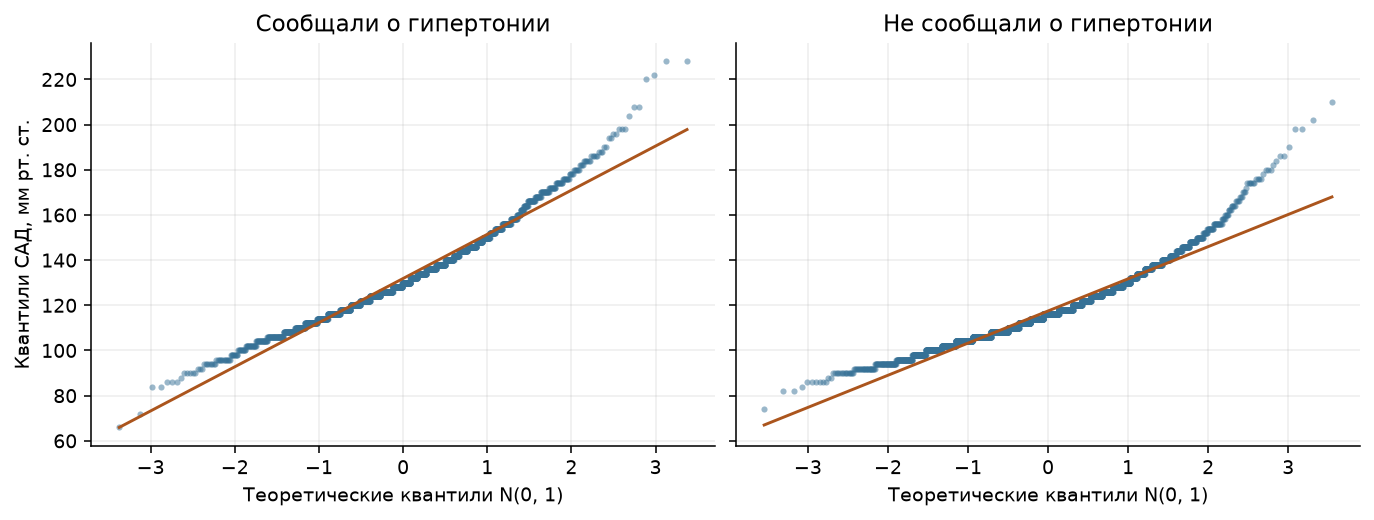

In [10]:
yes = welch_data.loc[welch_data["Ответ"].eq("Да"), "BPXSY1"].to_numpy(dtype=float)
no = welch_data.loc[welch_data["Ответ"].eq("Нет"), "BPXSY1"].to_numpy(dtype=float)
display(pd.DataFrame({
    "Сообщали": describe(yes),
    "Не сообщали": describe(no),
}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(9.7, 3.6), sharey=True, layout="constrained")
qq_plot(axes[0], yes, "Сообщали о гипертонии", f"Квантили САД, {unit}")
qq_plot(axes[1], no, "Не сообщали о гипертонии", "")
plt.show()

У обеих групп есть правые хвосты, более выраженные в группе «нет» (асимметрия 1,118 против 0,746). Разброс выше в группе «да» (19,82 против 14,65 мм рт. ст.). При 1 867 и 3 554 наблюдениях умеренная асимметрия и крайние точки не препятствуют приближению распределения разности средних к нормальному в модели независимых наблюдений.

In [11]:
welch_test = stats.ttest_ind(yes, no, equal_var=False, alternative="two-sided")
yes_var, no_var = yes.var(ddof=1), no.var(ddof=1)
v_yes, v_no = yes_var / yes.size, no_var / no.size
welch_df = (v_yes + v_no)**2 / (v_yes**2 / (yes.size - 1) + v_no**2 / (no.size - 1))
welch_effect = yes.mean() - no.mean()
welch_ci = t_interval(welch_effect, np.sqrt(v_yes + v_no), welch_df)
welch_d = welch_effect / np.sqrt((yes_var + no_var) / 2)
report_t(
    welch_test, f"«Да»: n₁ = {yes.size}, «нет»: n₂ = {no.size}.",
    welch_effect, welch_ci, welch_d, "d",
)
print(f"|d| = {abs(welch_d):.3f}.")

«Да»: n₁ = 1867, «нет»: n₂ = 3554.
t = 27.6324, df = 2962.203, p = 9.844e-150.
Эффект = +14.381 мм рт. ст., 95% ДИ [13.361; 15.402] мм рт. ст.
d = +0.825. Отвергаем H₀.
|d| = 0.825.


**Вывод по тесту Уэлча.** У сообщавших о гипертонии среднее первое САД выше на 14,381 мм рт. ст. (95% ДИ [13,361; 15,402]). Модуль $d=0{,}825$ соответствует большой стандартизированной разности по ориентировочной шкале Коэна. Этот результат описывает различие групп в данных.

### 5.3. Парный t-тест первого и второго измерений

Определяем $D_i=\mathrm{BPXSY2}_i-\mathrm{BPXSY1}_i$ для участника $i$ с обоими показаниями в той же строке SEQN. Проверяем $H_0:\mu_D=0$ против $H_1:\mu_D\ne0$. Нулевая гипотеза утверждает отсутствие среднего сдвига от первого показания ко второму. Альтернативная гипотеза допускает ненулевой сдвиг в любую сторону. В t-тест передаём второе показание первым аргументом. Для интервала используем $SE_D=s_D/\sqrt{n_D}$ и $n_D-1$ степеней свободы, для эффекта — $d_z=\bar D/s_D$.

По протоколу NHANES перед измерениями участник пять минут отдыхал сидя. Оба показания получены в рамках одного визита в мобильный центр обследования.

,Второе минус первое
n,5351.000
Среднее,-0.305
Медиана,0.000
s (ddof=1),5.538
Q1,-4.000
Q2,0.000
Q3,2.000
Минимум,-42.000
Максимум,34.000
Асимметрия,-0.141


Второе ниже: 2361. Равны: 834. Второе выше: 2156. Медиана |разности|: 4 мм рт. ст.


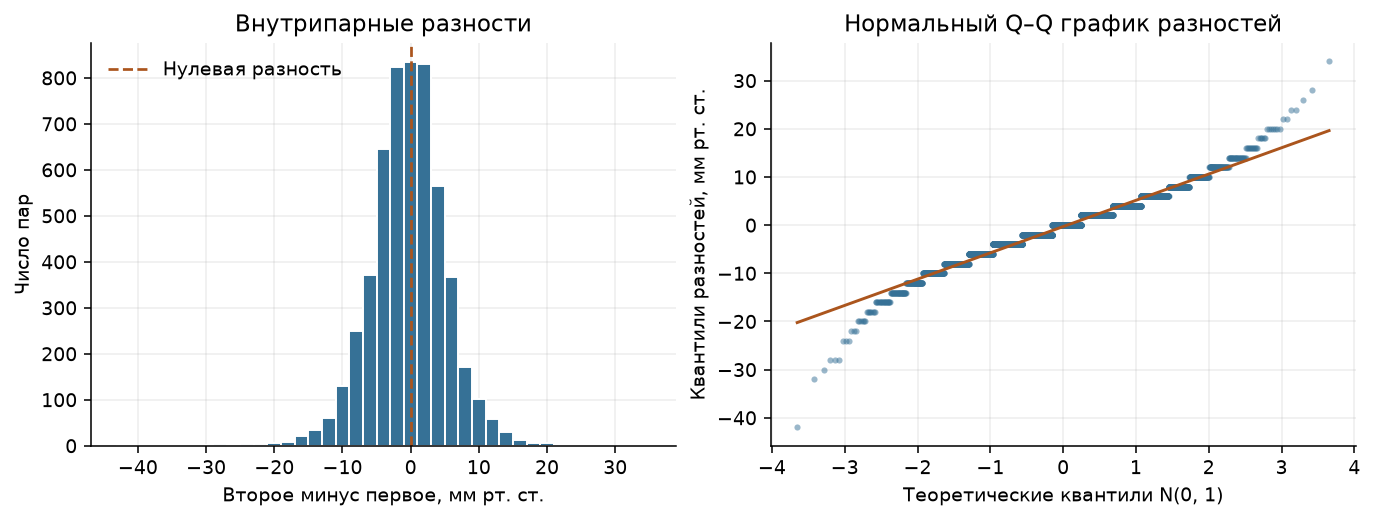

In [12]:
pair_values = paired[["BPXSY1", "BPXSY2"]].to_numpy(dtype=float)
first_pair, second_pair = pair_values.T
diff = second_pair - first_pair
n_pairs = diff.size
display(pd.DataFrame({"Второе минус первое": describe(diff)}).round(3))

print(f"Второе ниже: {(diff < 0).sum()}. Равны: {(diff == 0).sum()}. "
      f"Второе выше: {(diff > 0).sum()}. Медиана |разности|: {np.median(abs(diff)):g} {unit}")
fig, axes = plt.subplots(1, 2, figsize=(9.7, 3.6), layout="constrained")
axes[0].hist(diff, bins=np.arange(diff.min() - 1, diff.max() + 2, 2),
             color=blue, edgecolor="white")
axes[0].axvline(0, color=orange, lw=1.4, linestyle="--", label="Нулевая разность")
axes[0].set(title="Внутрипарные разности", xlabel=f"Второе минус первое, {unit}",
            ylabel="Число пар")
axes[0].legend()
qq_plot(axes[1], diff, "Нормальный Q–Q график разностей", f"Квантили разностей, {unit}")
plt.show()

Разности концентрируются у нуля и имеют небольшую левую асимметрию (−0,141). Ступеньки и отклонения в хвостах Q–Q графика отражают округление и крайние разности. При $n_D=5351$ применяем t-приближение к среднему разностей. Оно использует независимость между участниками в принятой модели и учитывает зависимость двух измерений внутри участника.

In [13]:
paired_test = stats.ttest_rel(second_pair, first_pair, alternative="two-sided")
diff_test = stats.ttest_1samp(diff, popmean=0, alternative="two-sided")
paired_effect = diff.mean()
sd_diff = diff.std(ddof=1)
paired_ci = t_interval(paired_effect, sd_diff / np.sqrt(n_pairs), n_pairs - 1)
paired_d = paired_effect / sd_diff
report_t(paired_test, f"Полных пар: {n_pairs}.", paired_effect, paired_ci, paired_d, "d_z")
print(f"Одновыборочная проверка тех же разностей: t = {diff_test.statistic:.4f}, "
      f"df = {diff_test.df}, p = {diff_test.pvalue:.3e}.")

Полных пар: 5351.
t = -4.0332, df = 5350.000, p = 5.579e-05.
Эффект = -0.305 мм рт. ст., 95% ДИ [-0.454; -0.157] мм рт. ст.
d_z = -0.055. Отвергаем H₀.
Одновыборочная проверка тех же разностей: t = -4.0332, df = 5350, p = 5.579e-05.


**Вывод по парному t-тесту.** Второе САД в среднем на 0,305 мм рт. ст. ниже первого, 95% ДИ для изменения [−0,454; −0,157]. Различие статистически обнаружимо в учебной модели. При $|d_z|=0{,}055$ и медиане абсолютной разности 4 мм рт. ст. средний сдвиг мал на фоне разброса изменений. Малый средний сдвиг совместим с более крупными изменениями у отдельных людей. Данные показывают порядок двух показаний во время одного визита, поэтому вывод относится к разности этих показаний.

### 5.4. Критерий χ² независимости

Обозначим $A$ возрастную группу, $R$ — ответ о гипертонии. Проверяем $H_0:P(A=i,R=j)=P(A=i)P(R=j)$ для всех ячеек. При $H_0$ возрастная группа и ответ независимы. Альтернатива $H_1$ утверждает, что равенство нарушено хотя бы для одной ячейки, то есть ответ связан с возрастной группой.

Каждый участник включён в одну ячейку. При независимости ожидаемая частота $E_{ij}=n_{i\cdot}n_{\cdot j}/N$. Проверим порог 5 для всех ячеек. Используем критерий Пирсона с `correction=False`. Для таблицы $3\times2$ число степеней свободы равно 2, поэтому коррекция Йейтса, предназначенная для одной степени свободы, здесь неприменима. Силу связи оцениваем $V=\sqrt{\chi^2/(N\min(r-1,c-1))}$, где $r$ и $c$ — размеры таблицы.

Возрастные группы 18–39, 40–59 и 60+ лет соответствуют возрастным группам отчёта NCHS.

In [14]:
age_labels = ["18–39", "40–59", "60+"]
chi_data["Возрастная группа"] = pd.cut(
    chi_data["RIDAGEYR"], bins=[18, 40, 60, np.inf], labels=age_labels, right=False,
)
observed = pd.crosstab(
    chi_data["Возрастная группа"], chi_data["Ответ"]
).reindex(index=age_labels, columns=["Да", "Нет"])
chi = stats.chi2_contingency(observed, correction=False)
expected = pd.DataFrame(chi.expected_freq, index=observed.index, columns=observed.columns)
chi_n = int(observed.to_numpy().sum())
cramer_v = np.sqrt(chi.statistic / (chi_n * (min(observed.shape) - 1)))
yes_percent = 100 * observed["Да"] / observed.sum(axis=1)
print("Наблюдаемые частоты")
display(observed.assign(Всего=observed.sum(axis=1), **{"Доля «да», %": yes_percent.round(2)}))
print("Ожидаемые частоты при независимости")
display(expected.round(2))
print(f"N = {chi_n}, минимум наблюдаемой частоты = {observed.to_numpy().min()}, "
      f"минимум ожидаемой частоты = {expected.to_numpy().min():.2f}.")
print(f"χ² = {chi.statistic:.4f}, df = {chi.dof}, p = {chi.pvalue:.3e}, "
      f"V Крамера = {cramer_v:.3f}. {decision(chi.pvalue)}.")

Наблюдаемые частоты


Ответ,Да,Нет,Всего,"Доля «да», %"
Возрастная группа,,,,
18–39,288,2009,2297,12.54
40–59,702,1272,1974,35.56
60+,1170,667,1837,63.69


Ожидаемые частоты при независимости


Ответ,Да,Нет
Возрастная группа,,
18–39,812.30,1484.70
40–59,698.07,1275.93
60+,649.63,1187.37


N = 6108, минимум наблюдаемой частоты = 288, минимум ожидаемой частоты = 649.63.
χ² = 1168.4842, df = 2, p = 1.849e-254, V Крамера = 0.437. Отвергаем H₀.


**Вывод по критерию χ².** Все наблюдаемые и ожидаемые частоты выше 5. Доля сообщавших о гипертонии выросла от 12,54% в группе 18–39 лет до 35,56% в группе 40–59 и 63,69% в группе 60+. $V=0{,}437$ и разница крайних возрастных групп примерно в 51 процентный пункт показывают выраженную связь возраста с ответом. Считаем долю самоотчётов в выборке. Связь указывает, что возраст стоит учитывать при содержательном сравнении групп по BPQ020.

### 5.5. Поправка Холма и сводная таблица

Семейство состоит из четырёх проверок по пересекающимся выборкам этого обследования: сравнения с 120, сравнения групп по BPQ020, сравнения двух показаний и проверки связи BPQ020 с возрастом. Поправка Холма контролирует вероятность хотя бы одного ошибочного отвержения в семействе на уровне 0,05 при корректной калибровке исходных p-значений и допускает зависимость тестов. Для упорядоченных p-значений $p_{(j)}$ используем $\tilde p_{(i)}=\min(1,\max_{j\le i}[(m-j+1)p_{(j)}])$ при $m=4$.

В таблице 95% ДИ для t-тестов приведены для эффекта в мм рт. ст. Это обычные индивидуальные интервалы. Сопоставляем их с исходными двусторонними p-значениями. Для χ² приводим оценку $V$ Крамера.

In [15]:
results = pd.DataFrame([
    ("Одновыборочный t", str(n), "t", one_test.statistic, one_test.df, one_test.pvalue,
     f"{one_effect:+.3f}", format_ci(one_ci), f"d = {one_d:+.3f}"),
    ("Уэлча", f"{yes.size} / {no.size}", "t", welch_test.statistic, welch_test.df,
     welch_test.pvalue, f"{welch_effect:+.3f}", format_ci(welch_ci), f"d = {welch_d:+.3f}"),
    ("Парный t", f"{n_pairs} пар", "t", paired_test.statistic, paired_test.df,
     paired_test.pvalue, f"{paired_effect:+.3f}", format_ci(paired_ci), f"d_z = {paired_d:+.3f}"),
    ("χ² Пирсона", str(chi_n), "χ²", chi.statistic, chi.dof, chi.pvalue,
     "—", "—", f"V = {cramer_v:.3f}"),
], columns=[
    "Проверка", "Объём", "Критерий", "Статистика", "df", "p",
    "Эффект, мм рт. ст.", "95% ДИ эффекта", "Станд. эффект",
]).set_index("Проверка")

ordered_p = results["p"].sort_values()
m = len(ordered_p)
holm = np.minimum(1, np.maximum.accumulate(ordered_p.to_numpy() * np.arange(m, 0, -1)))
results["p Холма"] = pd.Series(holm, index=ordered_p.index)
results["Решение без поправки"] = results["p"].map(decision)
results["Решение Холма"] = results["p Холма"].map(decision)
formatted_results = results.round({"Статистика": 4, "df": 3}).copy()
for column in ["p", "p Холма"]:
    formatted_results[column] = results[column].map("{:.3e}".format)
display(formatted_results)

,Объём,Критерий,Статистика,df,p,"Эффект, мм рт. ст.",95% ДИ эффекта,Станд. эффект,p Холма,Решение без поправки,Решение Холма
Проверка,,,,,,,,,,,
Одновыборочный t,5426,t,10.0507,5425.000,1.465e-23,+2.452,[1.973; 2.930],d = +0.136,2.929e-23,Отвергаем H₀,Отвергаем H₀
Уэлча,1867 / 3554,t,27.6324,2962.203,9.844e-150,+14.381,[13.361; 15.402],d = +0.825,2.953e-149,Отвергаем H₀,Отвергаем H₀
Парный t,5351 пар,t,-4.0332,5350.000,5.579e-05,-0.305,[-0.454; -0.157],d_z = -0.055,5.579e-05,Отвергаем H₀,Отвергаем H₀
χ² Пирсона,6108,χ²,1168.4842,2.000,1.849e-254,—,—,V = 0.437,7.395e-254,Отвергаем H₀,Отвергаем H₀


In [16]:
# Проверка воспроизводимости и согласия расчётов
assert t99[1] - t99[0] >= t95[1] - t95[0]
assert t99[0] <= t95[0] <= t95[1] <= t99[1]
np.testing.assert_allclose((boot_normal[0] + boot_normal[1]) / 2, x_mean)
repeat_means, repeat_medians = bootstrap(x, B, seed, batch_size)
np.testing.assert_array_equal(boot_means, repeat_means)
np.testing.assert_array_equal(boot_medians, repeat_medians)

np.testing.assert_allclose(one_test.confidence_interval(), t95)
np.testing.assert_allclose(welch_test.confidence_interval(), welch_ci)
np.testing.assert_allclose(paired_test.confidence_interval(), paired_ci)
np.testing.assert_allclose(welch_test.df, welch_df)
np.testing.assert_allclose(
    [paired_test.statistic, paired_test.df, paired_test.pvalue],
    [diff_test.statistic, diff_test.df, diff_test.pvalue],
    atol=0,
)
np.testing.assert_allclose(diff_test.confidence_interval(), paired_ci)
for result, interval, null in [
    (one_test, t95, mu0), (welch_test, welch_ci, 0), (paired_test, paired_ci, 0),
]:
    lo, hi = interval
    assert (result.pvalue < alpha) == (null < lo - 1e-10 or null > hi + 1e-10)

assert chi_n == len(chi_data) and chi.dof == 2
assert (expected.to_numpy() >= 5).all()
np.testing.assert_allclose(expected.sum(axis=0), observed.sum(axis=0))
np.testing.assert_allclose(expected.sum(axis=1), observed.sum(axis=1))
assert results["p Холма"].ge(results["p"]).all()
print("Подтверждены воспроизводимость бутстрепа, вложенность t-интервалов, согласие "
      "трёх t-тестов с интервалами, равенство проверок парных разностей и расчёт частот χ².")

Подтверждены воспроизводимость бутстрепа, вложенность t-интервалов, согласие трёх t-тестов с интервалами, равенство проверок парных разностей и расчёт частот χ².


## 6. Выводы по работе

1. **Первое измерение САД.** Среднее у 5 426 взрослых составило 122,45 мм рт. ст. 95% t-интервал равен [121,97; 122,93] мм рт. ст. Все три 95% интервала для среднего лежат выше ориентира 120 мм рт. ст. Выбор между t-интервалом и бутстрепом здесь не меняет вывод. Медиана первого показания равна 120 мм рт. ст., её процентильный ДИ — [118; 120].
2. **Изменение между двумя показаниями.** В 5 351 полной паре второе САД в среднем на 0,305 мм рт. ст. ниже первого. 95% ДИ для изменения равен [−0,454; −0,157], $p$ после поправки Холма составляет $5{,}579\cdot10^{-5}$. Парный t-тест лучше всего отвечает на основной вопрос, поскольку сопоставляет измерения одного участника. При $|d_z|=0{,}055$ и медиане абсолютной разности 4 мм рт. ст. средний сдвиг невелик.
3. **Сравнение групп.** У сообщавших о гипертонии среднее первое САД выше на 14,38 мм рт. ст. ($d=0{,}825$). Доля ответов «да» связана с возрастной группой ($V=0{,}437$). Решения по всем четырём тестам сохраняются после поправки Холма.
4. **Интерпретация.** При многократном повторении выборки около 95% интервалов, рассчитанных тем же способом, содержали бы фиксированный параметр при выполнении предпосылок. p-значение — вероятность при $H_0$ получить результат не менее экстремальный, чем наблюдаемый. Для двустороннего t-теста учитываем оба хвоста по $|t|$, для χ² — верхний хвост.
5. **Ограничения.** Анализ касается взрослых в одном цикле NHANES. У 687 взрослых отсутствовало первое измерение, поэтому оценки могут зависеть от того, у кого удалось измерить давление. Ответ о гипертонии основан на самоотчёте. Возраст и лечение могут влиять на межгрупповую разность. Для оценок по населению США нужны веса и учёт плана обследования.